# Phase 3 — Retrieval Mechanism (which retriever, which K, which fallback)

**Purpose.** Phase 2 showed exact-key blocking is far too expensive (~80 B pairs for 94 % recall). Phase 3 decides how each S1 record
will find its true S2/S3 matches among ~10 M records: which TF-IDF retriever, which K, whether an address route is needed, and whether the
engine can scale.

**Discipline.**
- Train entities only; `val_ground_truth.tsv` is never opened.
- 3,000 query entities, split into half **A** (used to *choose*) and half **B** (used to *confirm*).
- Retrieval is **same-country only** (Phase 2 measured 100 % country agreement on true pairs).
- Pool = every true match of the query entities **plus** a random fraction of all other S2/S3 rows (the distractors).
  Recall is measured at 2 %, 5 % and 10 % distractor pools and **extrapolated** to 100 %, because the full 10 M pool does not fit in memory.
- Every choice is made by a printed numeric criterion.

**Sections:** 1 Data → 2 Retriever grid → 3 Address route → 4 Pool-size curve + K → 5 Subgroups and misses → 6 Engine scalability → 7 Config + summary

In [1]:
import os, sys, re, time, json, pickle, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize as sk_normalize

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import normalization_v2 as nv
import retrieval_engine as RE

ROOT = "../../../"
TRAIN_DIR = ROOT + "dataset/train"; SPLIT_DIR = ROOT + "dataset/split"; INTERIM = ROOT + "dataset/interim"
os.makedirs(INTERIM, exist_ok=True)
CFG = nv.load_config()
NAME_RULES, ADDR_RULES = CFG["name_rules"], CFG["addr_rules"]
print("normalization config:", CFG["name_rules"], "|", CFG["addr_rules"])

SEED, NQ, KMAX = 42, 3000, 100
POOL_FRACS = [0.02, 0.05, 0.10]
KS = [1, 5, 10, 20, 30, 50, 100]
pd.set_option("display.width", 170)
plt.rcParams["figure.dpi"] = 100

normalization config: ['accent_strip', 'lowercase', 'whitespace_collapse', 'suffix_canonicalize', 'domain_strip', 'punct_strip', 'whitespace_final'] | ['abbrev_expand', 'punct_strip', 'token_sort']


## 1. Data: query entities, true pairs, nested distractor pools

Queries come from the Phase 2 sample (train entities with ≥ 1 match). The S2/S3 files are streamed once to draw a random 10 % distractor pool;
each distractor gets a uniform number `u ∈ [0, 0.10)`, so the 2 % and 5 % pools are exact subsets of the 10 % pool.

In [2]:
P2 = INTERIM + "/phase2_sample.pkl"
assert os.path.exists(P2), "run the Phase 2 notebook first (it builds dataset/interim/phase2_sample.pkl)"
S2 = pickle.load(open(P2, "rb"))
tp_all = S2["tp"]
train_ids = set(open(SPLIT_DIR + "/train_s1_ids.txt").read().split())
assert set(tp_all["source1_entity_id"]) <= train_ids

ents = tp_all["source1_entity_id"].drop_duplicates().sample(NQ, random_state=SEED).tolist()
q = (tp_all.drop_duplicates("source1_entity_id").set_index("source1_entity_id").loc[ents]
          .reset_index()[["source1_entity_id", "s1_name", "s1_addr", "country"]])
q["half"] = np.where(np.arange(NQ) % 2 == 0, "A", "B")
qpos = {e: i for i, e in enumerate(q["source1_entity_id"])}
tpq = tp_all[tp_all["source1_entity_id"].isin(set(ents))].reset_index(drop=True)
tpq["qi"] = tpq["source1_entity_id"].map(qpos)
tpq["half"] = q["half"].values[tpq["qi"].values]
print(f"queries: {NQ:,} | true pairs: {len(tpq):,} | pairs per entity: {len(tpq)/NQ:.2f} | train-only: True")

POOL_CACHE = INTERIM + "/phase3_pool.pkl"
sig = json.dumps(CFG, sort_keys=True)
pool = None
if os.path.exists(POOL_CACHE):
    c = pickle.load(open(POOL_CACHE, "rb"))
    if c["sig"] == sig and c["ents"] == ents:
        pool = c["pool"]; print("loaded cached normalized pool")
if pool is None:
    t0 = time.time()
    wanted = set(tpq["m_id"])
    def scan(path, frac, seed):
        r = np.random.default_rng(seed); out = []
        for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, chunksize=500_000):
            u = r.random(len(ch)); m = (u < frac) & (~ch["entity_id"].isin(wanted)).values
            d = ch[m].copy(); d["u"] = u[m]; out.append(d)
        return pd.concat(out)
    d = pd.concat([scan(TRAIN_DIR + "/train_source2.tsv", max(POOL_FRACS), SEED),
                   scan(TRAIN_DIR + "/train_source3.tsv", max(POOL_FRACS), SEED + 1)])
    d = d.rename(columns={"entity_id": "id", "business_name": "name", "business_address": "addr"})
    tr = (tpq.drop_duplicates("m_id")[["m_id", "m_name", "m_addr", "m_country"]]
          .rename(columns={"m_id": "id", "m_name": "name", "m_addr": "addr", "m_country": "country"}))
    tr["u"] = -1.0
    pool = pd.concat([tr, d[["id", "name", "addr", "country", "u"]]], ignore_index=True)
    print(f"pool scanned in {time.time()-t0:.0f}s: {len(pool):,} rows; normalizing...")
    t0 = time.time()
    pool["name_n"] = [nv.normalize_name(x, rules=NAME_RULES) for x in pool["name"]]
    pool["addr_n"] = [nv.normalize_addr(x, rules=ADDR_RULES) for x in pool["addr"]]
    print(f"normalized in {time.time()-t0:.0f}s")
    pickle.dump(dict(sig=sig, ents=ents, pool=pool), open(POOL_CACHE, "wb"))
q["name_n"] = [nv.normalize_name(x, rules=NAME_RULES) for x in q["s1_name"]]
q["addr_n"] = [nv.normalize_addr(x, rules=ADDR_RULES) for x in q["s1_addr"]]
pool["gi"] = np.arange(len(pool))
gi_of = dict(zip(pool["id"], pool["gi"]))
tpq["target"] = tpq["m_id"].map(gi_of)
assert tpq["target"].notna().all()
tpq["target"] = tpq["target"].astype(int)
N_FULL_DISTRACT = S2["n_s23_total"]
for f in POOL_FRACS:
    print(f"pool @ {f:.0%}: {int((pool.u < f).sum()):,} rows")

NON_ASCII = re.compile(r"[^\x00-\x7F]")
tpq["nonascii"] = tpq["s1_name"].str.contains(NON_ASCII) | tpq["m_name"].str.contains(NON_ASCII)
tpq["addr_missing"] = (tpq["s1_addr"].str.strip() == "") | (tpq["m_addr"].str.strip() == "")
tpq["src"] = tpq["m_id"].str[:2]

queries: 3,000 | true pairs: 10,945 | pairs per entity: 3.65 | train-only: True


loaded cached normalized pool


pool @ 2%: 217,101 rows
pool @ 5%: 526,423 rows
pool @ 10%: 1,041,767 rows


### Evaluation machinery
`run(spec, frac)` builds TF-IDF matrices (name and/or address, optionally weighted and stacked), retrieves the top 100 same-country pool rows
per query, and returns the rank of each true match (999 if outside the top 100). Index-build and search time are measured separately.

In [3]:
def build_mats(spec, ps):
    parts_p, parts_q = [], []
    for key, col_p, col_q, w in (("name", "name_n", "name_n", spec.get("wn", 1.0)),
                                 ("addr", "addr_n", "addr_n", spec.get("wa", 1.0))):
        if spec.get(key) is None: continue
        kind, ng, mdf, sub = spec[key]
        v = RE.make_vectorizer(kind, ng, mdf, sub)
        Xp = v.fit_transform(ps[col_p]); Xq = v.transform(q[col_q])
        if spec.get("name") is not None and spec.get("addr") is not None:
            Xp, Xq = Xp * np.sqrt(w), Xq * np.sqrt(w)
        parts_p.append(Xp); parts_q.append(Xq)
    if len(parts_p) == 1: return parts_p[0], parts_q[0]
    return sp.hstack(parts_p).tocsr(), sp.hstack(parts_q).tocsr()

RUN_CACHE = INTERIM + "/phase3_runs.pkl"
_runs = pickle.load(open(RUN_CACHE, "rb")) if os.path.exists(RUN_CACHE) else {}

def run(spec, frac, label=""):
    ckey = json.dumps([label, frac, spec, NQ, SEED, sig], default=str)
    if ckey in _runs:
        return _runs[ckey]
    out = _run(spec, frac, label)
    _runs[ckey] = out
    pickle.dump(_runs, open(RUN_CACHE, "wb"))
    return out

def _run(spec, frac, label=""):
    ps = pool[pool["u"] < frac].reset_index(drop=True)
    t0 = time.perf_counter(); Pm, Qm = build_mats(spec, ps); t_build = time.perf_counter() - t0
    t0 = time.perf_counter()
    idx = RE.topk_by_country(Qm, Pm, q["country"].values, ps["country"].values, k=KMAX)
    t_search = time.perf_counter() - t0
    top_gi = np.where(idx >= 0, ps["gi"].values[np.clip(idx, 0, None)], -1)
    ranks = np.full(len(tpq), 999)
    for j, (qi, t) in enumerate(zip(tpq["qi"].values, tpq["target"].values)):
        w = np.flatnonzero(top_gi[qi] == t)
        if len(w): ranks[j] = w[0] + 1
    return dict(label=label, ranks=ranks, build_s=t_build, search_s=t_search, n_pool=len(ps),
                nnz_per_row=Pm.nnz / max(Pm.shape[0], 1))

def recall_at(ranks, ks=KS, mask=None):
    r = ranks if mask is None else ranks[mask]
    return {f"R@{k}": float((r <= k).mean()) for k in ks}

mA, mB = (tpq["half"] == "A").values, (tpq["half"] == "B").values
RESULTS = {}

## 2. Name retriever grid (2 % pool, choose on half A)

Variants: char n-gram range (2–4 vs 3–5), sublinear TF, and **DF pruning** (`max_df=0.05` drops n-grams present in > 5 % of names — they carry little
discriminative weight and make sparse products very expensive), plus a word-level baseline.

**Criteria (printed below):**
1. Best name variant = highest `R@20` on half A among unpruned variants.
2. Its pruned counterpart is **accepted** for the engine if `R@20` loss ≤ 0.005 **and** search time ≥ 1.5× faster.

char24             done in     0s
char24_sub         done in     0s
char35             done in     0s
char24_pruned      done in     0s
char24sub_pruned   done in     0s
char35_pruned      done in     0s
word12             done in     0s


,R@1,R@5,R@10,R@20,R@30,R@50,R@100,build_s,search_s,nnz_per_row
variant,,,,,,,,,,
char24,0.2381,0.7117,0.7819,0.8177,0.8329,0.8520,0.8689,10.1227,13.0548,60.3636
char24_sub,0.2372,0.7117,0.7831,0.8161,0.8316,0.8522,0.8689,8.5847,13.2960,60.3636
char35,0.2372,0.6909,0.7588,0.7944,0.8123,0.8316,0.8548,9.7986,6.2912,51.4237
char24_pruned,0.2314,0.6963,0.7691,0.8099,0.8261,0.8413,0.8611,8.4218,4.2869,36.5840
char24sub_pruned,0.2316,0.7002,0.7706,0.8099,0.8261,0.8416,0.8611,9.5353,4.3465,36.5840
char35_pruned,0.2296,0.6824,0.7510,0.7908,0.8120,0.8289,0.8511,8.9579,3.7199,44.3551
word12,0.2355,0.6829,0.7439,0.7738,0.7879,0.7996,0.8135,3.2284,2.9995,6.1308


best unpruned: char24 (R@20=0.8177)
pruned counterpart char24_pruned: R@20 loss=+0.0078 (need <= 0.005), speed-up=3.05x (need >= 1.5x) -> REJECT pruning
NAME RETRIEVER SELECTED: char24
confirmation on half B: R@20 = 0.8073 vs half A 0.8177 -> DIVERGES (>0.01)


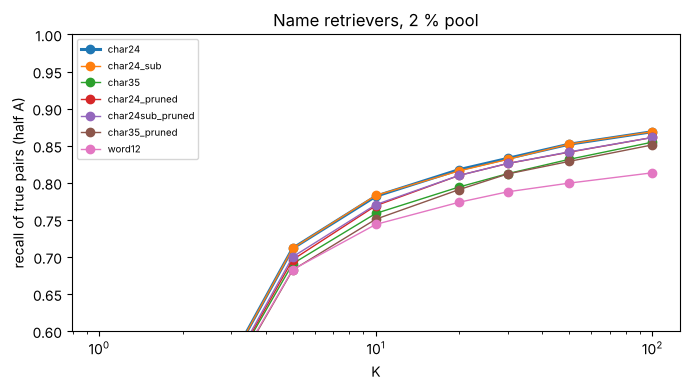

In [4]:
FRAC0 = 0.02
GRID = {
    "char24":          dict(name=("char", (2, 4), 1.0, False)),
    "char24_sub":      dict(name=("char", (2, 4), 1.0, True)),
    "char35":          dict(name=("char", (3, 5), 1.0, False)),
    "char24_pruned":   dict(name=("char", (2, 4), 0.05, False)),
    "char24sub_pruned": dict(name=("char", (2, 4), 0.05, True)),
    "char35_pruned":   dict(name=("char", (3, 5), 0.05, False)),
    "word12":          dict(name=("word", (1, 2), 1.0, False)),
}
for k, spec in GRID.items():
    t0 = time.time(); RESULTS[(k, FRAC0)] = run(spec, FRAC0, k)
    print(f"{k:18s} done in {time.time()-t0:5.0f}s")

rows = []
for k in GRID:
    r = RESULTS[(k, FRAC0)]
    rows.append(dict(variant=k, **recall_at(r["ranks"], mask=mA), build_s=r["build_s"], search_s=r["search_s"], nnz_per_row=r["nnz_per_row"]))
tab = pd.DataFrame(rows).set_index("variant")
display(tab.round(4))

unpruned = [k for k in GRID if "pruned" not in k and k != "word12"]
best_unpruned = max(unpruned, key=lambda k: tab.loc[k, "R@20"])
counterpart = {"char24": "char24_pruned", "char24_sub": "char24sub_pruned", "char35": "char35_pruned"}[best_unpruned]
loss = tab.loc[best_unpruned, "R@20"] - tab.loc[counterpart, "R@20"]
speed = tab.loc[best_unpruned, "search_s"] / tab.loc[counterpart, "search_s"]
ACCEPT_PRUNE = bool(loss <= 0.005 and speed >= 1.5)
NAME_BEST = counterpart if ACCEPT_PRUNE else best_unpruned
print(f"best unpruned: {best_unpruned} (R@20={tab.loc[best_unpruned,'R@20']:.4f})")
print(f"pruned counterpart {counterpart}: R@20 loss={loss:+.4f} (need <= 0.005), speed-up={speed:.2f}x (need >= 1.5x) -> {'ACCEPT' if ACCEPT_PRUNE else 'REJECT'} pruning")
print("NAME RETRIEVER SELECTED:", NAME_BEST)
conf = recall_at(RESULTS[(NAME_BEST, FRAC0)]["ranks"], mask=mB)
print(f"confirmation on half B: R@20 = {conf['R@20']:.4f} vs half A {tab.loc[NAME_BEST,'R@20']:.4f} "
      f"-> {'consistent' if abs(conf['R@20']-tab.loc[NAME_BEST,'R@20'])<=0.01 else 'DIVERGES (>0.01)'}")

fig, ax = plt.subplots(figsize=(7, 4))
for k in GRID:
    ax.plot(KS, [tab.loc[k, f"R@{x}"] for x in KS], marker="o", label=k, lw=2.2 if k == NAME_BEST else 1)
ax.set_xscale("log"); ax.set_xlabel("K"); ax.set_ylabel("recall of true pairs (half A)"); ax.set_ylim(0.6, 1)
ax.legend(fontsize=7); ax.set_title("Name retrievers, 2 % pool"); plt.tight_layout(); plt.show()

## 3. Address route (fallback for pairs whose names differ too much)

Phase 2 showed ~6 % of true pairs share no name key; many of those still share an address. Candidates:
- `addr_only`: word TF-IDF on the normalized address (pruned `max_df=0.05` to drop "street/road/…"), empty address → no candidates.
- `combined`: stacked name + address vectors (0.7 / 0.3), one ranking.

**Criteria:** union route = name top-K1 ∪ route top-K2. Adopt the union if recall improves by ≥ 0.01 at ≤ +10 extra candidates per query
(K1 = 20 fixed; K2 ∈ {5, 10}). Choose the route with the better union recall at K2 = 10. Judged on half A, confirmed on B.

In [5]:
nm = GRID[NAME_BEST]["name"]
ROUTES = {
    "addr_only": dict(addr=("word", (1, 1), 0.05, False)),
    "combined":  dict(name=nm, addr=("word", (1, 1), 0.05, False), wn=0.7, wa=0.3),
}
for k, spec in ROUTES.items():
    t0 = time.time(); RESULTS[(k, FRAC0)] = run(spec, FRAC0, k); print(f"{k:10s} done in {time.time()-t0:4.0f}s")

def union_recall(r1, r2, K1, K2, mask):
    a, b = r1["ranks"][mask], r2["ranks"][mask]
    return float(((a <= K1) | (b <= K2)).mean())

rn = RESULTS[(NAME_BEST, FRAC0)]
rows = []
for k in ROUTES:
    rr = RESULTS[(k, FRAC0)]
    rows.append(dict(route=k, alone_R20=float((rr["ranks"][mA] <= 20).mean()),
                     union_K2_5=union_recall(rn, rr, 20, 5, mA), union_K2_10=union_recall(rn, rr, 20, 10, mA),
                     union_K2_20=union_recall(rn, rr, 20, 20, mA)))
rt = pd.DataFrame(rows).set_index("route")
base20 = float((rn["ranks"][mA] <= 20).mean())
print(f"name-only R@20 (half A): {base20:.4f}")
display(rt.round(4))
ROUTE_BEST = rt["union_K2_10"].idxmax()
gain = rt.loc[ROUTE_BEST, "union_K2_10"] - base20
ADOPT_UNION = bool(gain >= 0.01)
K2 = 10 if ADOPT_UNION else 0
conf_gain = union_recall(rn, RESULTS[(ROUTE_BEST, FRAC0)], 20, 10, mB) - float((rn["ranks"][mB] <= 20).mean())
print(f"best route: {ROUTE_BEST}; union(K1=20,K2=10) gain over name-only = {gain:+.4f} (need >= +0.010) -> {'ADOPT' if ADOPT_UNION else 'REJECT'}")
print(f"confirmation on half B: gain = {conf_gain:+.4f}")

addr_only  done in    0s
combined   done in    0s
name-only R@20 (half A): 0.8177


,alone_R20,union_K2_5,union_K2_10,union_K2_20
route,,,,
addr_only,0.9192,0.9733,0.9829,0.9855
combined,0.9039,0.8726,0.8967,0.9039


best route: addr_only; union(K1=20,K2=10) gain over name-only = +0.1652 (need >= +0.010) -> ADOPT
confirmation on half B: gain = +0.1778


## 4. Joint choice of K (name K1, address K2) and the pool-size curve

**Joint K criterion (10 % pool, all 3,000 queries):** the candidate list is `name top-K1 ∪ address top-K2`. Among combinations with
`K1 + K2 ≤ 60` (the candidate budget per query), pick the **cheapest** one whose recall is within 0.005 of the best recall in the grid.
(If the address route was not adopted, K1 is chosen alone: smallest K whose next step adds < 0.005.)

**Pool-size curve:** the chosen combination is measured at 2 %, 5 %, 10 % pools and `miss = a + b·ln(#distractors)` is fitted to extrapolate to the
full 10.3 M pool (an **assumption**, shown with the 3 points it rests on).

char24 @ 5%: 0s (build 23s, search 32s)
char24 @ 10%: 0s (build 41s, search 62s)
addr_only @ 5%: 0s (build 6s, search 6s)
addr_only @ 10%: 0s (build 11s, search 11s)
best recall in grid (budget 60): 0.9803


,K1,K2,recall
cost,,,
5,0,5,0.8132
10,5,5,0.9315
15,5,10,0.9582
20,10,10,0.9660
25,5,20,0.9646
30,20,10,0.9716
35,5,30,0.9684
40,20,20,0.9759
50,20,30,0.9784


CHOSEN: K1 (name) = 20, K2 (address) = 20  (cost 40/query, recall 0.9759)


,distractors,name_R20,chosen_union
pool,,,
2%,206156,0.8124,0.9866
5%,515478,0.7827,0.9820
10%,1030822,0.7510,0.9759


,extrapolated_to_full_pool,miss_slope_per_ln(N)
name_R20,0.6658,0.0378
chosen_union,0.9614,0.0066


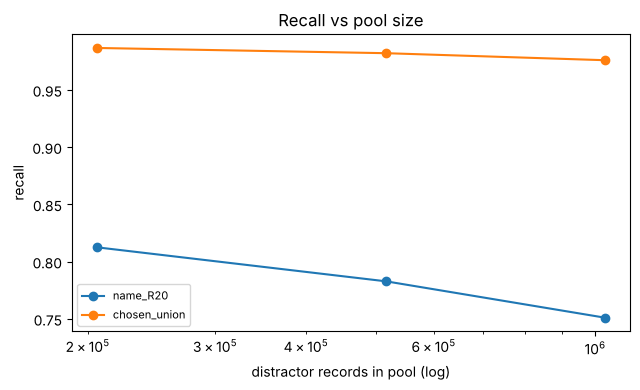

=> ~40 candidates/query; full train candidate pairs ~ 71 M


In [6]:
need = [(NAME_BEST, f) for f in POOL_FRACS] + ([(ROUTE_BEST, f) for f in POOL_FRACS] if ADOPT_UNION else [])
for k, f in need:
    if (k, f) in RESULTS: continue
    spec = {**GRID, **ROUTES}[k]
    t0 = time.time(); RESULTS[(k, f)] = run(spec, f, k); print(f"{k} @ {f:.0%}: {time.time()-t0:.0f}s (build {RESULTS[(k,f)]['build_s']:.0f}s, search {RESULTS[(k,f)]['search_s']:.0f}s)")

f10 = max(POOL_FRACS)
r10 = RESULTS[(NAME_BEST, f10)]["ranks"]
BUDGET = 60
if ADOPT_UNION:
    ra10 = RESULTS[(ROUTE_BEST, f10)]["ranks"]
    GK = [0, 5, 10, 20, 30, 50]
    g = pd.DataFrame([dict(K1=a, K2=b, cost=a + b, recall=float(((r10 <= a) | (ra10 <= b)).mean())) for a in GK for b in GK if 0 < a + b <= BUDGET])
    best_r = g["recall"].max()
    pick = g[g["recall"] >= best_r - 0.005].sort_values(["cost", "recall"], ascending=[True, False]).iloc[0]
    K, K2 = int(pick["K1"]), int(pick["K2"])
    print("best recall in grid (budget %d): %.4f" % (BUDGET, best_r))
    display(g.loc[g.groupby("cost")["recall"].idxmax()].set_index("cost").round(4))
    print(f"CHOSEN: K1 (name) = {K}, K2 (address) = {K2}  (cost {K+K2}/query, recall {pick['recall']:.4f})")
else:
    cands = [10, 20, 30, 50, 100]
    rr = {k: float((r10 <= k).mean()) for k in cands}
    K = next((k for i, k in enumerate(cands[:-1]) if rr[cands[i + 1]] - rr[k] < 0.005), cands[-1]); K2 = 0
    print("CHOSEN K =", K)
rec10 = {k: float((r10 <= k).mean()) for k in [5, 10, 20, 50, 100]}

def chosen_hit(f):
    r = RESULTS[(NAME_BEST, f)]["ranks"]
    return (r <= K) | (RESULTS[(ROUTE_BEST, f)]["ranks"] <= K2) if ADOPT_UNION else (r <= K)

nd = {f: int((pool.u.between(0, f - 1e-12)).sum()) for f in POOL_FRACS}
curve = pd.DataFrame([dict(pool=f"{f:.0%}", distractors=nd[f],
                           name_R20=float((RESULTS[(NAME_BEST, f)]["ranks"] <= 20).mean()),
                           chosen_union=float(chosen_hit(f).mean())) for f in POOL_FRACS]).set_index("pool")
display(curve.round(4))

def extrapolate(vals, ns, n_full):
    x = np.log(np.array(ns, float)); y = 1 - np.array(vals)
    b, a = np.polyfit(x, y, 1)
    return float(1 - (a + b * np.log(n_full))), float(b)
ext = {c: extrapolate(curve[c].values, curve["distractors"].values, S2["n_s23_total"]) for c in ["name_R20", "chosen_union"]}
display(pd.DataFrame(ext, index=["extrapolated_to_full_pool", "miss_slope_per_ln(N)"]).T.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
for c in ["name_R20", "chosen_union"]:
    ax.plot(curve["distractors"], curve[c], marker="o", label=c)
ax.set_xscale("log"); ax.set_xlabel("distractor records in pool (log)"); ax.set_ylabel("recall"); ax.legend(fontsize=8)
ax.set_title("Recall vs pool size"); plt.tight_layout(); plt.show()
print(f"=> ~{K+K2} candidates/query; full train candidate pairs ~ {(K+K2)*S2['n_s1_train']/1e6:,.0f} M")

## 5. Where does retrieval fail? (10 % pool, all queries)
Subgroup recall at the chosen K, then a breakdown of misses.

In [7]:
rk = RESULTS[(NAME_BEST, f10)]["ranks"]
hit = rk <= K
hit_u = chosen_hit(f10)
tpq["hit_name"], tpq["hit_final"], tpq["rank_name"] = hit, hit_u, rk
sub = []
for col in ["nonascii", "addr_missing", "country", "src"]:
    for v, g in tpq.groupby(col):
        sub.append(dict(group=f"{col}={v}", n=len(g), recall_name=g["hit_name"].mean(), recall_final=g["hit_final"].mean()))
sub.insert(0, dict(group="ALL", n=len(tpq), recall_name=hit.mean(), recall_final=hit_u.mean()))
subdf = pd.DataFrame(sub).set_index("group"); display(subdf.round(4))

per_ent = tpq.groupby("qi").agg(n=("hit_final", "size"), found=("hit_final", "sum"))
print(f"entity level: >=1 true match found: {(per_ent.found>0).mean():.2%} | ALL true matches found: {(per_ent.found==per_ent.n).mean():.2%}")

miss = tpq[~tpq["hit_final"]].copy()
_edges = [K] + [e for e in (50, 100) if e > K] + [999]
_labels = [f"{a+1}-{b}" if b < 999 else f">{a}" for a, b in zip(_edges[:-1], _edges[1:])]
miss["bucket"] = pd.cut(miss["rank_name"], _edges, labels=_labels)
print(f"\nmissed pairs: {len(miss):,} ({len(miss)/len(tpq):.2%}). Rank buckets (name route):")
print(miss["bucket"].value_counts().sort_index().to_string())
print("non-ASCII among misses: %.1f%% | address missing among misses: %.1f%%" % (100*miss.nonascii.mean(), 100*miss.addr_missing.mean()))
display(miss.sample(min(10, len(miss)), random_state=1)[["s1_name", "m_name", "s1_addr", "m_addr", "rank_name"]])

,n,recall_name,recall_final
group,,,
ALL,10945,0.7510,0.9759
nonascii=False,9338,0.8022,0.9831
nonascii=True,1607,0.4536,0.9340
addr_missing=False,10441,0.7459,0.9816
addr_missing=True,504,0.8571,0.8571
country=India,4377,0.6616,0.9598
country=US,6568,0.8106,0.9866
src=S2,5146,0.7392,0.9790
src=S3,5799,0.7615,0.9731


entity level: >=1 true match found: 99.87% | ALL true matches found: 92.60%

missed pairs: 264 (2.41%). Rank buckets (name route):
bucket
21-50      35
51-100     21
>100      208
non-ASCII among misses: 40.2% | address missing among misses: 27.3%


,s1_name,m_name,s1_addr,m_addr,rank_name
3975,Chiropractic Cascade Associates,Chiropractic Associates Center #67279,"220 County Rd 792, Etowah, TN",,999
733,Shivam It Private Limited,Shri Shivam Private Limited Partners,"Webel It Park, Tower 2, 3Rd Floor Module No 30...","Block D-605 Webel It Park, পশ্চিমবঙ্গ",999
7062,Modern Enterprises Pvt Ltd,मॉडर्न एंटरप्राइजेज प्रा. लि.,"61/4, Manoramaganj, Indore, Madhya Pradesh","61/4, Indore, MP",999
7254,Sree Technologies Private Limited,श्री टेक्नोलॉजीज प्राइवेट लिमिटेड,"F-129/5, Abul Fazal, Enclave Part-2, New Delhi...","DORO NO 989. F-129/5, NEW DELHI, दिल्ली",999
2206,Christ Emanuel,Christ Eanncl,"2811 Main Street, Ventura, CA",,999
10605,Atkins Autism Assistance Harbor Fellowship Inc,Assistanceautism.Com,"208 15th Street, Atkins, AR","00208 15st St, Atkins, Arkansas",999
9164,Pacific League,Pacific League Corporation,"150 Second Street, Albany, NY",,24
7108,Bison LLC,Bison Trading,"611 Menelaus Road, Berea, KY",,97
3170,City Tirupati Media Private Limited,सिटी तिरुपति मीडिया प्राइवेट लिमिटेड,"2Nd Floor, Shanbramha Complex Opp. Faraskhana ...","DOR NO A-216, PUNE, Maharashtra",999
4895,Capital Liberty Jaws P.C.,Capital Lbioesyt Jaws P.C.,"222 Fourth Street, New Cumberland Borough, PA","0222 4TH ST, NEW CUMBERLAND, PA",73


## 6. Engine scalability
Search time per query was measured on the 10 % pool (~1 M records, same-country, 100 k-row chunks, 256-query batches).
Brute-force sparse search scales ~linearly with pool size, so the full pool costs ~10× per query.

In [8]:
rows = []
for k in {NAME_BEST, best_unpruned, counterpart}:
    if (k, f10) not in RESULTS: RESULTS[(k, f10)] = run({**GRID}[k], f10, k)
    r = RESULTS[(k, f10)]
    ms = 1000 * r["search_s"] / NQ
    scale = S2["n_s23_total"] / r["n_pool"]
    hours_train = ms / 1000 * scale * S2["n_s1_train"] / 3600
    rows.append(dict(variant=k, ms_per_query_10pct=ms, nnz_per_row=r["nnz_per_row"], R20=float((r["ranks"] <= 20).mean()),
                     projected_hours_train_1core=hours_train))
eng = pd.DataFrame(rows).set_index("variant"); display(eng.round(3))
P_BYTES = eng.loc[NAME_BEST, "nnz_per_row"] * S2["n_s23_total"] * 8 / 1e9
print(f"index memory at full pool (CSR float32+int32): ~{P_BYTES:.1f} GB for the name matrix alone")
print("Same-country split halves each query's search space; the 2-core machine here would roughly halve the projected hours if run in parallel.")

,ms_per_query_10pct,nnz_per_row,R20,projected_hours_train_1core
variant,,,,
char24,20.631,60.445,0.751,100.229
char24_pruned,6.741,36.591,0.748,32.750


index memory at full pool (CSR float32+int32): ~5.0 GB for the name matrix alone
Same-country split halves each query's search space; the 2-core machine here would roughly halve the projected hours if run in parallel.


### 6b. Cheaper engine: pruning sweep (2 % pool, half A)
Both routes are re-run with progressively stronger DF pruning (`max_df`). The union uses the K1/K2 chosen above.
**Criterion:** the cheapest (name + address search time) combination whose union recall is within 0.005 of the unpruned-name + address(0.05) baseline.
Projection = ms/query at the 2 % pool × (full pool / 2 % pool) × train queries ÷ 3600 (single core, assumes search time ∝ pool size).

In [9]:
nspec = GRID[NAME_BEST]["name"]
NAME_MDF = [1.0, 0.05, 0.01, 0.002]
ADDR_MDF = [0.05, 0.01, 0.002]
sw_name, sw_addr = {}, {}
for m in NAME_MDF:
    sw_name[m] = run(dict(name=(nspec[0], nspec[1], m, nspec[3])), FRAC0, f"sweep_name_{m}")
for m in ADDR_MDF:
    sw_addr[m] = run(dict(addr=("word", (1, 1), m, False)), FRAC0, f"sweep_addr_{m}")
scale = S2["n_s23_total"] / sw_name[1.0]["n_pool"]
rows = []
for mn in NAME_MDF:
    for ma in ADDR_MDF:
        a_, b_ = sw_name[mn], sw_addr[ma]
        rec = float(((a_["ranks"][mA] <= K) | (b_["ranks"][mA] <= K2)).mean())
        ms = 1000 * (a_["search_s"] + b_["search_s"]) / NQ
        rows.append(dict(name_max_df=mn, addr_max_df=ma, union_recall_A=rec, ms_per_query=ms,
                         projected_hours_1core=ms / 1000 * scale * S2["n_s1_train"] / 3600))
swp = pd.DataFrame(rows)
base_rec = swp[(swp.name_max_df == 1.0) & (swp.addr_max_df == 0.05)]["union_recall_A"].iloc[0]
ok = swp[swp["union_recall_A"] >= base_rec - 0.005].sort_values("ms_per_query")
display(swp.round(4))
ENG = ok.iloc[0]
print(f"baseline union recall (half A) = {base_rec:.4f}")
print(f"CHEAPEST WITHIN 0.005: name max_df={ENG.name_max_df}, addr max_df={ENG.addr_max_df}: recall {ENG.union_recall_A:.4f}, "
      f"{ENG.ms_per_query:.1f} ms/query -> ~{ENG.projected_hours_1core:.0f} core-hours for all train queries (~{ENG.projected_hours_1core/2:.0f} h on 2 cores)")
if ENG.projected_hours_1core > 12:
    print("WARNING: still heavy for brute-force sparse search; Phase 4 must shard by country, run in parallel, and/or cap the query set "
          "(see summary).")

,name_max_df,addr_max_df,union_recall_A,ms_per_query,projected_hours_1core
0,1.000,0.050,0.9855,5.1412,119.8511
1,1.000,0.010,0.9833,5.0381,117.4487
2,1.000,0.002,0.9774,4.9033,114.3070
3,0.050,0.050,0.9850,2.2466,52.3726
4,0.050,0.010,0.9829,2.1435,49.9702
5,0.050,0.002,0.9766,2.0088,46.8285
6,0.010,0.050,0.9818,1.6216,37.8024
7,0.010,0.010,0.9796,1.5185,35.4000
8,0.010,0.002,0.9726,1.3838,32.2583
9,0.002,0.050,0.9690,1.4854,34.6284


baseline union recall (half A) = 0.9855
CHEAPEST WITHIN 0.005: name max_df=0.01, addr max_df=0.05: recall 0.9818, 1.6 ms/query -> ~38 core-hours for all train queries (~19 h on 2 cores)


## 7. Config and summary

In [10]:
cfg_out = {
    "same_country_only": True,
    "name_vectorizer": {"kind": nm[0], "ngram": list(nm[1]), "max_df": float(ENG.name_max_df), "sublinear_tf": nm[3], "variant": NAME_BEST},
    "K_name": int(K),
    "address_route": ({"kind": "word", "ngram": [1, 1], "max_df": float(ENG.addr_max_df), "route": ROUTE_BEST,
                       "K_addr": int(K2), "weights": {"wn": 0.7, "wa": 0.3} if ROUTE_BEST == "combined" else None}
                      if ADOPT_UNION else None),
    "normalization_config": CFG,
    "measured": {"recall_name_10pct_pool": rec10, "recall_final_10pct_pool": float(hit_u.mean()),
                 "extrapolated_full_pool": {k: v[0] for k, v in ext.items()},
                 "projected_core_hours_train": float(ENG.projected_hours_1core)},
    "criteria": {"prune": "R@20 loss<=0.005 and speedup>=1.5x", "union": "gain>=0.01 at <=+10 candidates",
                 "K": "cheapest (K1,K2) with K1+K2<=60 within 0.005 of best recall",
                 "engine": "cheapest max_df pair within 0.005 union recall"},
}
json.dump(cfg_out, open("retrieval_config.json", "w"), indent=2)
print("=== PHASE 3 SUMMARY ===")
print("Retriever     :", NAME_BEST, "| pruning", "accepted" if ACCEPT_PRUNE else "rejected")
print("Address route :", (ROUTE_BEST + f" (K2={K2})") if ADOPT_UNION else "not adopted")
print(f"K             : name K1={K}, address K2={K2}  -> ~{K+K2} candidates/query")
print(f"Engine        : name max_df={ENG.name_max_df}, addr max_df={ENG.addr_max_df}; ~{ENG.projected_hours_1core:.0f} core-hours for all train queries")
print(f"Recall (10% pool, pair-level): name-only {hit.mean():.2%} | final {hit_u.mean():.2%}")
for k, v in ext.items(): print(f"  extrapolated to full pool, {k}: {v[0]:.2%}")
print("Config written: retrieval_config.json. No validation labels were used.")

=== PHASE 3 SUMMARY ===
Retriever     : char24 | pruning rejected
Address route : addr_only (K2=20)
K             : name K1=20, address K2=20  -> ~40 candidates/query
Engine        : name max_df=0.01, addr max_df=0.05; ~38 core-hours for all train queries
Recall (10% pool, pair-level): name-only 75.10% | final 97.59%
  extrapolated to full pool, name_R20: 66.58%
  extrapolated to full pool, chosen_union: 96.14%
Config written: retrieval_config.json. No validation labels were used.
